In [15]:
import os
import glob
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from safetensors.torch import load_file
import numpy as np

# Set style
sns.set_theme(style="white")

# ============================================================================
# Configuration Cell
# ============================================================================

# Dataset Configuration (use HuggingFace name)
# DATASET_NAME = "l11p/VQAv2-COCO-restval-ICQ"
DATASET_NAME="l11p/COCOQA-restval-ICQA"
# Automatic prefix detection (same as Python scripts)
DATASET_PREFIX = DATASET_NAME.split("/")[-1].replace(".", "_").replace("-", "_").lower()

# Models Configuration (HuggingFace names)
MODELS = {
    "Pretrained": "l11p/llava-v1.5-7b-pretrained-liuhaotian",
    "Finetuned": "llava-hf/llava-1.5-7b-hf"
}
# Extract model IDs (used in filenames)
MODEL_IDS = {k: v.split("/")[-1] for k, v in MODELS.items()}

# Dataset Variants
DATASET_VARIANTS = ["img"]

# Analysis Parameters
POOLING_METHODS = ["mean_image"]

# Paths
RESULTS_DIR = Path("../results/model_comparison/intra_model_similarities")
PLOTS_DIR = Path("../plots/intra_model_similarity")
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"📊 Configuration loaded:")
print(f"  Dataset: {DATASET_NAME}")
print(f"  Prefix: {DATASET_PREFIX}")
print(f"  Models: {list(MODELS.values())}")
print(f"  Pooling: {POOLING_METHODS}")
print(f"  Variants: {DATASET_VARIANTS}")

📊 Configuration loaded:
  Dataset: l11p/COCOQA-restval-ICQA
  Prefix: cocoqa_restval_icqa
  Models: ['l11p/llava-v1.5-7b-pretrained-liuhaotian', 'llava-hf/llava-1.5-7b-hf']
  Pooling: ['mean_image']
  Variants: ['img']


In [16]:
def load_intra_similarity_data(model_id, dataset_variant, pooling_method):
    """
    Load intra-model similarity data for a specific model and dataset.
    
    The Python script computes the lower triangular part and the diagonal (i >= j).
    This function reconstructs the full symmetric matrix by mirroring.
    
    Args:
        model_id: Model identifier (e.g., 'llava-1.5-7b-hf')
        dataset_variant: 'img' or 'txt'
        pooling_method: 'last', 'mean_image', etc.
    
    Returns:
        Dictionary mapping measure names to symmetric similarity matrices
    """
    dataset_name = f"{DATASET_PREFIX}_{dataset_variant}"
    
    # Pattern to find all measure files for this model config
    # Filename format: {model_id}_{dataset}_{pooling}_{measure}_intra_similarity.safetensors
    pattern = str(RESULTS_DIR / f"{model_id}_{dataset_name}_{pooling_method}_*_intra_similarity.safetensors")
    files = glob.glob(pattern)
    
    if not files:
        print(f"⚠️  No intra-similarity files found for {model_id} on {dataset_name} ({pooling_method})")
        print(f"    Pattern: {pattern}")
        print(f"    Hint: Run intra_model_similarity.py first")
        return {}
    
    data = {}
    for fpath in files:
        # Extract measure name from filename
        filename = os.path.basename(fpath)
        prefix = f"{model_id}_{dataset_name}_{pooling_method}_"
        suffix = "_intra_similarity.safetensors"
        
        if filename.startswith(prefix) and filename.endswith(suffix):
            measure = filename[len(prefix):-len(suffix)]
            
            try:
                loaded = load_file(fpath)
                # The stored key is the measure name
                if measure in loaded:
                    matrix = loaded[measure].float().numpy()
                    
                    # Reconstruct full symmetric matrix
                    # The script computes lower triangular part + diagonal (i >= j)
                    num_layers = matrix.shape[0]
                    
                    # Create full symmetric matrix
                    full_matrix = np.zeros((num_layers, num_layers), dtype=matrix.dtype)
                    
                    # Copy lower triangular part and diagonal
                    for i in range(num_layers):
                        for j in range(i + 1):
                            full_matrix[i, j] = matrix[i, j]
                    
                    # Mirror to upper triangular part (above diagonal)
                    for i in range(num_layers):
                        for j in range(i + 1, num_layers):
                            full_matrix[i, j] = full_matrix[j, i]
                    
                    data[measure] = full_matrix
                else:
                    print(f"⚠️  Key '{measure}' not found in {filename}")
            except Exception as e:
                print(f"⚠️  Error loading {filename}: {e}")
    
    return data


def plot_intra_similarity_heatmaps(model_label, model_id, dataset_variant, pooling_method):
    """
    Create a grid of heatmaps showing intra-model similarity for different measures.
    
    Args:
        model_label: Human-readable label (e.g., 'Pretrained', 'Finetuned')
        model_id: Model identifier for file loading
        dataset_variant: 'img' or 'txt'
        pooling_method: 'last', 'mean_image', etc.
    """
    dataset_name = f"{DATASET_PREFIX}_{dataset_variant}"
    measures = load_intra_similarity_data(model_id, dataset_variant, pooling_method)
    
    if not measures:
        print(f"⚠️  Skipping plot for {model_label} ({dataset_name}, {pooling_method}) - no data found")
        return
    
    # Filter out invalid measures
    measures = {k: v for k, v in measures.items() if v is not None and v.size > 0}
    
    if not measures:
        print(f"⚠️  No valid measures for {model_label} ({dataset_name}, {pooling_method})")
        return
    
    num_measures = len(measures)
    cols = 3
    rows = (num_measures + cols - 1) // cols
    
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4.5 * rows))
    if num_measures == 1:
        axes = np.array([axes])
    axes = np.array(axes).flatten()
    
    # Title with variant info
    variant_label = "Image QA" if dataset_variant == "img" else "Text QA"
    fig.suptitle(
        f"Intra-Model Similarity: {model_label} | {variant_label} | {pooling_method}",
        fontsize=16, fontweight='bold', y=0.995
    )
    
    for i, (measure, matrix) in enumerate(sorted(measures.items())):
        ax = axes[i]
        
        # Format measure name for display
        measure_title = measure.replace("_", " ").title()
        
        sns.heatmap(
            matrix,
            ax=ax,
            cmap="viridis",
            square=True,
            xticklabels=False,
            yticklabels=False,
            cbar_kws={'shrink': 0.8},
            vmin=0,
            vmax=1
        )
        ax.set_title(measure_title, fontsize=12, pad=8)
        ax.set_xlabel("Layer Index (j)", fontsize=10)
        ax.set_ylabel("Layer Index (i)", fontsize=10)
        
        
    
    # Hide empty subplots
    for i in range(num_measures, len(axes)):
        axes[i].axis('off')
    
    plt.tight_layout()
    
    # Save plot
    save_path = PLOTS_DIR / f"intra_similarity_{model_id}_{dataset_name}_{pooling_method}.png"
    plt.savefig(save_path, dpi=300, bbox_inches="tight", facecolor='white')
    print(f"✅ Saved plot to {save_path}")
    plt.show()


def plot_all_intra_similarities():
    """
    Generate all intra-model similarity plots for all combinations of models, 
    dataset variants, and pooling methods.
    """
    print("=" * 80)
    print("🎨 Generating Intra-Model Similarity Plots")
    print("=" * 80)
    
    for pooling in POOLING_METHODS:
        print(f"\n📊 Pooling method: {pooling}")
        print("-" * 80)
        
        for variant in DATASET_VARIANTS:
            variant_label = "Image QA" if variant == "img" else "Text QA"
            print(f"  Dataset variant: {variant_label}")
            
            for model_label, model_path in MODELS.items():
                model_id = MODEL_IDS[model_label]
                print(f"    → {model_label} ({model_id})...")
                plot_intra_similarity_heatmaps(model_label, model_id, variant, pooling)
    
    print("\n" + "=" * 80)
    print("✅ All intra-model similarity plots generated!")
    print("=" * 80)

🎨 Generating Intra-Model Similarity Plots

📊 Pooling method: mean_image
--------------------------------------------------------------------------------
  Dataset variant: Image QA
    → Pretrained (llava-v1.5-7b-pretrained-liuhaotian)...


✅ Saved plot to ../plots/intra_model_similarity/intra_similarity_llava-v1.5-7b-pretrained-liuhaotian_cocoqa_restval_icqa_img_mean_image.png


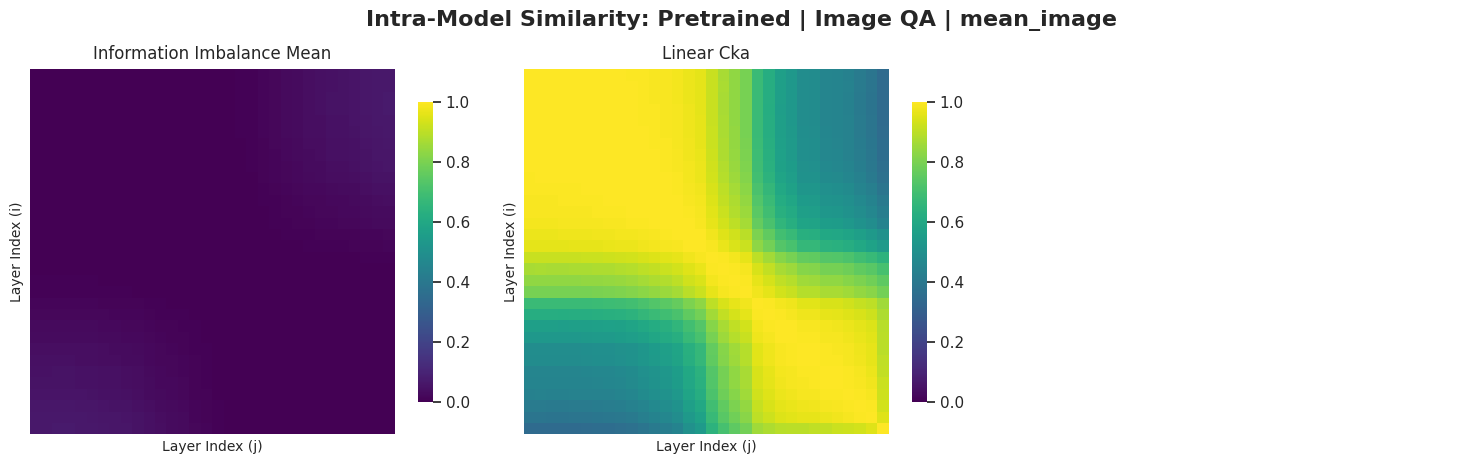

    → Finetuned (llava-1.5-7b-hf)...
✅ Saved plot to ../plots/intra_model_similarity/intra_similarity_llava-1.5-7b-hf_cocoqa_restval_icqa_img_mean_image.png


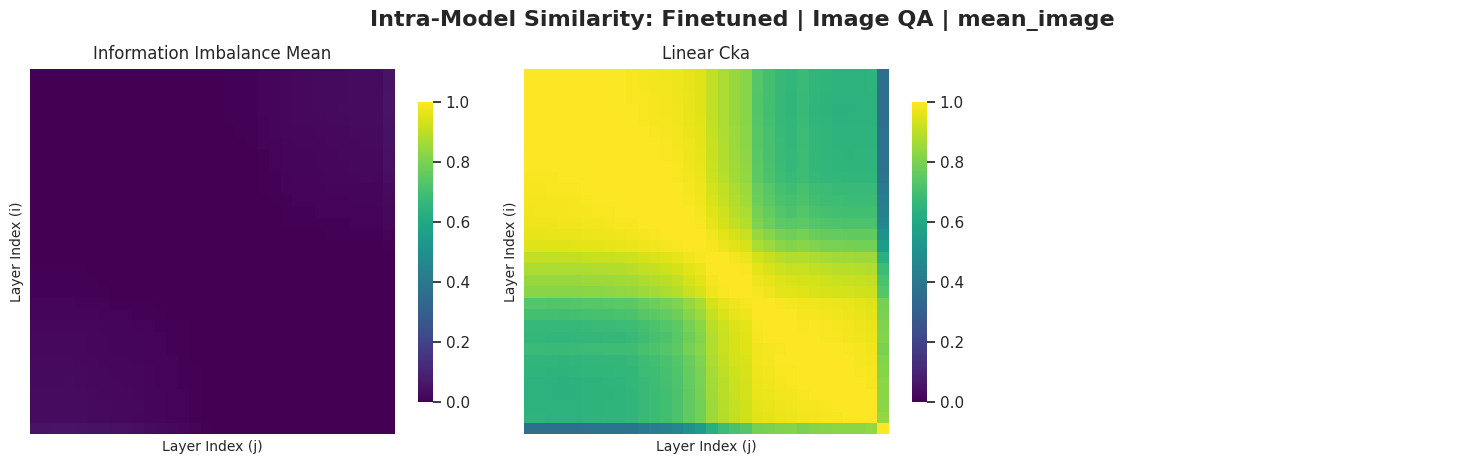


✅ All intra-model similarity plots generated!


In [17]:
# Generate all intra-model similarity plots
plot_all_intra_similarities()

Loading /u/dssc/lpalaciosflores/multimodal_finetuned_representations/results/model_comparison/intra_model_similarities/llava-v1.5-7b-pretrained-liuhaotian_cocoqa_restval_icqa_img_mean_image_linear_cka_intra_similarity.safetensors...
Similarity between layers i and i+5: [0.9993203, 0.9989398, 0.9986111, 0.9980706, 0.9975925, 0.9965278, 0.9952235, 0.9936873, 0.99137473, 0.98367995, 0.97787046, 0.9475792, 0.91875106, 0.89909166, 0.89645094, 0.83188903, 0.8626246, 0.8706074, 0.88725764, 0.88918656, 0.9542956, 0.963179, 0.9788633, 0.9786948, 0.97534627, 0.96325505, 0.91005206]
27


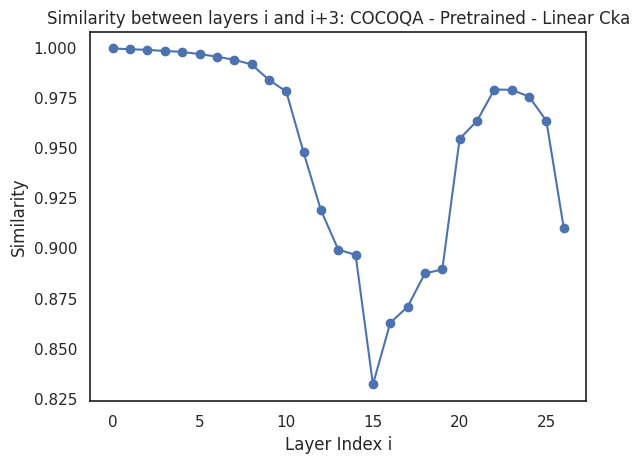

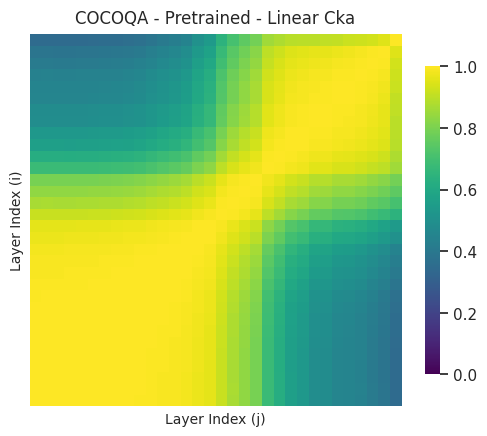

Loading /u/dssc/lpalaciosflores/multimodal_finetuned_representations/results/model_comparison/intra_model_similarities/llava-1.5-7b-hf_cocoqa_restval_icqa_img_mean_image_linear_cka_intra_similarity.safetensors...
Similarity between layers i and i+5: [0.99851507, 0.99729073, 0.9960862, 0.99464214, 0.9939503, 0.99334985, 0.9924235, 0.99166757, 0.98920596, 0.98201215, 0.9761986, 0.9432699, 0.92199916, 0.910053, 0.9164255, 0.87422085, 0.91282296, 0.92564267, 0.9390711, 0.95070195, 0.97883874, 0.98087054, 0.9870411, 0.98375416, 0.98616743, 0.98066896, 0.8170719]
27


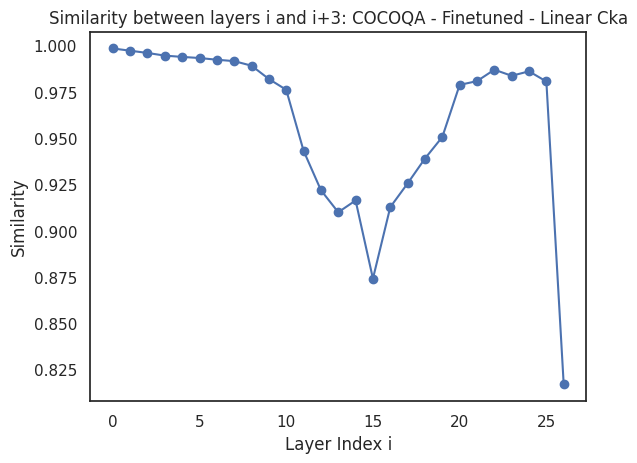

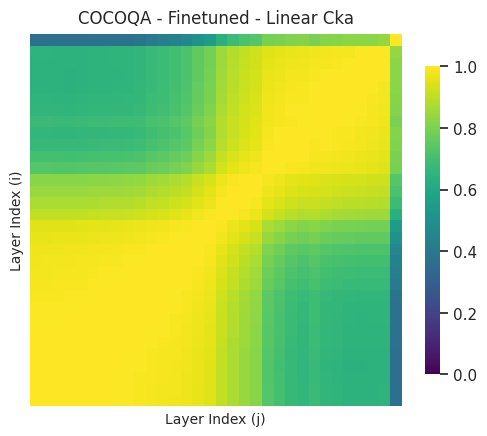

Loading /u/dssc/lpalaciosflores/multimodal_finetuned_representations/results/model_comparison/intra_model_similarities/llava-v1.5-7b-pretrained-liuhaotian_vqav2_coco_restval_icq_img_mean_image_linear_cka_intra_similarity.safetensors...
Similarity between layers i and i+5: [0.99933535, 0.9989612, 0.9986319, 0.9980932, 0.9976344, 0.9966957, 0.99552155, 0.9942391, 0.9921476, 0.9855492, 0.9802522, 0.95399237, 0.92817503, 0.9094457, 0.90570337, 0.8445296, 0.8688637, 0.87327576, 0.88907504, 0.88832337, 0.9520816, 0.9613992, 0.97747874, 0.9772472, 0.973901, 0.96131635, 0.905303]
27


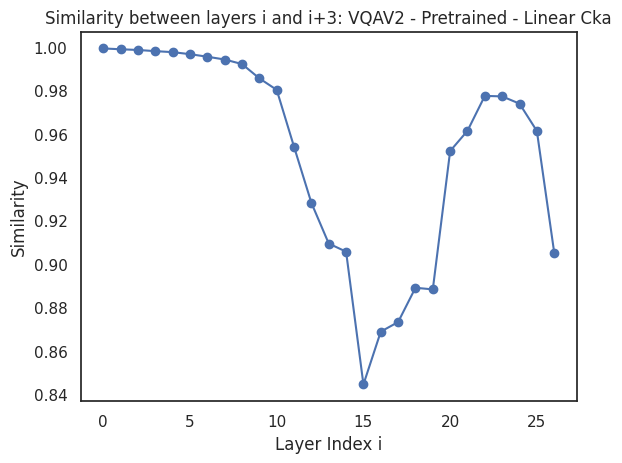

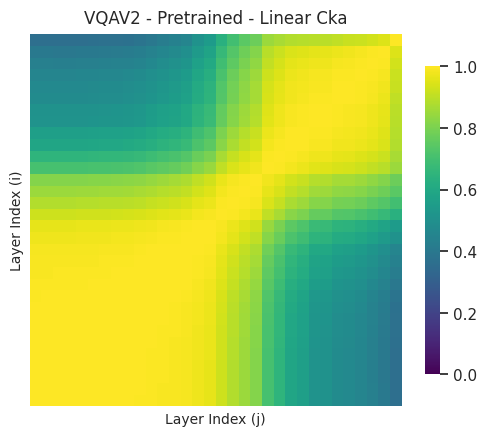

Loading /u/dssc/lpalaciosflores/multimodal_finetuned_representations/results/model_comparison/intra_model_similarities/llava-1.5-7b-hf_vqav2_coco_restval_icq_img_mean_image_linear_cka_intra_similarity.safetensors...
Similarity between layers i and i+5: [0.99859095, 0.9974212, 0.99629056, 0.9949416, 0.99431294, 0.99381137, 0.9930114, 0.9924175, 0.99021643, 0.98423064, 0.97893196, 0.9500363, 0.93048996, 0.91914904, 0.92314905, 0.8830302, 0.9171129, 0.92792964, 0.94043744, 0.95119536, 0.9787104, 0.9807136, 0.98700386, 0.983804, 0.98620796, 0.9808866, 0.80484116]
27


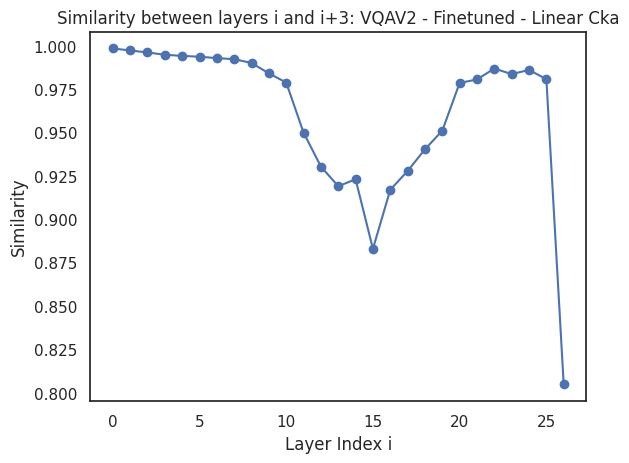

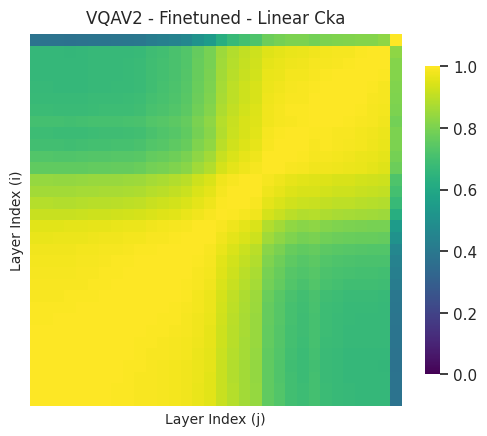

In [20]:
configs = {
    "cocoqa": {
        "pretrained": {
            "linear_cka": "/u/dssc/lpalaciosflores/multimodal_finetuned_representations/results/model_comparison/intra_model_similarities/llava-v1.5-7b-pretrained-liuhaotian_cocoqa_restval_icqa_img_mean_image_linear_cka_intra_similarity.safetensors",
            "information_imbalance_mean": "/u/dssc/lpalaciosflores/multimodal_finetuned_representations/results/model_comparison/intra_model_similarities/llava-v1.5-7b-pretrained-liuhaotian_cocoqa_restval_icqa_img_mean_image_information_imbalance_mean_intra_similarity.safetensors"
        },
        "finetuned": {
            "linear_cka": "/u/dssc/lpalaciosflores/multimodal_finetuned_representations/results/model_comparison/intra_model_similarities/llava-1.5-7b-hf_cocoqa_restval_icqa_img_mean_image_linear_cka_intra_similarity.safetensors",
            "information_imbalance_mean": "/u/dssc/lpalaciosflores/multimodal_finetuned_representations/results/model_comparison/intra_model_similarities/llava-1.5-7b-hf_cocoqa_restval_icqa_img_mean_image_information_imbalance_mean_intra_similarity.safetensors"
        },
    },
    "vqav2": {
        "pretrained": {
            "linear_cka": "/u/dssc/lpalaciosflores/multimodal_finetuned_representations/results/model_comparison/intra_model_similarities/llava-v1.5-7b-pretrained-liuhaotian_vqav2_coco_restval_icq_img_mean_image_linear_cka_intra_similarity.safetensors",
            "information_imbalance_mean": "/u/dssc/lpalaciosflores/multimodal_finetuned_representations/results/model_comparison/intra_model_similarities/llava-v1.5-7b-pretrained-liuhaotian_vqav2_coco_restval_icq_img_mean_image_information_imbalance_mean_intra_similarity.safetensors"
        },
        "finetuned": {
            "linear_cka": "/u/dssc/lpalaciosflores/multimodal_finetuned_representations/results/model_comparison/intra_model_similarities/llava-1.5-7b-hf_vqav2_coco_restval_icq_img_mean_image_linear_cka_intra_similarity.safetensors",
            "information_imbalance_mean": "/u/dssc/lpalaciosflores/multimodal_finetuned_representations/results/model_comparison/intra_model_similarities/llava-1.5-7b-hf_vqav2_coco_restval_icq_img_mean_image_information_imbalance_mean_intra_similarity.safetensors"
        },
    },
}

measures = ["linear_cka"]
datasets = ["cocoqa", "vqav2"]
models = ["pretrained", "finetuned"]

for dataset in datasets:
    for model in models:
        for measure in measures:
            path = configs[dataset][model][measure]
            print(f"Loading {path}...")
            
            try:
                loaded = load_file(path)[measure]
                # The stored key is the measure name
                matrix = loaded.float().numpy()

                # Reconstruct full symmetric matrix
                # The script computes lower triangular part + diagonal (i >= j)
                num_layers = matrix.shape[0]

                # Create full symmetric matrix
                full_matrix = np.zeros((num_layers, num_layers), dtype=matrix.dtype)

                similarity_layers_plus3 = []
                
                # Copy lower triangular part and diagonal
                for i in range(num_layers):
                    for j in range(i + 1):
                        full_matrix[i, j] = matrix[i, j]

                # Mirror to upper triangular part (above diagonal)
                for i in range(num_layers):
                    for j in range(i + 1, num_layers):
                        full_matrix[i, j] = full_matrix[j, i]
                        
                        
                for i in range(num_layers):
                    for j in range(num_layers):
                        if j == i + 5:
                            similarity_layers_plus3.append(full_matrix[i, j])
                            
                print("Similarity between layers i and i+5:", similarity_layers_plus3)
                print(len(similarity_layers_plus3))
                
                fig, ax = plt.subplots()
                ax.plot(range(len(similarity_layers_plus3)), similarity_layers_plus3, marker='o')
                ax.set_title(f"Similarity between layers i and i+3: {dataset.upper()} - {model.capitalize()} - {measure.replace('_', ' ').title()}")
                ax.set_xlabel("Layer Index i")
                ax.set_ylabel("Similarity")
                plt.show()
                        
                fig, ax = plt.subplots(figsize=(6, 5))
                sns.heatmap(
                    full_matrix,
                    ax=ax,
                    cmap="viridis",
                    square=True,
                    xticklabels=False,
                    yticklabels=False,
                    cbar_kws={'shrink': 0.8},
                    vmin=0,
                    vmax=1
                )
                ax.set_title(f"{dataset.upper()} - {model.capitalize()} - {measure.replace('_', ' ').title()}", fontsize=12, pad=8)
                ax.set_xlabel("Layer Index (j)", fontsize=10)
                ax.set_ylabel("Layer Index (i)", fontsize=10)
                ax.invert_yaxis()
                plt.show()
            except Exception as e:
                print(f"⚠️  Error loading or processing {path}: {e}")
                continue